# The surety market of public procurement in Colombia: insurers and contractors

**Objective:** every contractor of the Colombian State has to buy guarantees (pólizas de cumplimiento, seriedad de la oferta, responsabilidad civil...), and SECOP II publishes all of them. With this data we want to answer two questions for an insurance broker (Cuántico Agencia de Seguros): which insurers compete in this market and how, and which groups of contractors exist and how to approach each one.

**Data (datos.gov.co, Socrata API):**
- SECOP II - Garantías (`gjp9-cutm`), 7.1 million records, Colombia Compra Eficiente
- Solvencia individual aseguradoras (`ppux-25v5`), Superintendencia Financiera

The tables at contractor level have names, so they stay in `data/private/` and are not published. Only the aggregated results are in the repository.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests`, `re`, `unicodedata` and `scikit-learn`.

## Part 1. Libraries

In [1]:
import os
import re
import time
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data/private", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Download with SoQL

Only insurance policies (not bank guarantees) and insured values between 100.000 COP and 1 trillion COP (bigger values are typing errors). The `GROUP BY` can return more than 50.000 groups, so we always ask page by page.

In [2]:
url = "https://www.datos.gov.co/resource/gjp9-cutm.json"
valido = "tipopoliza = 'Contrato de Seguro' AND valor > 100000 AND valor < 1000000000000"

def anio(y):
    return f"{valido} AND fechadecreacionpoliza >= '{y}-01-01' AND fechadecreacionpoliza < '{y + 1}-01-01'"

def paginado(select, group, where, url=url):
    filas, offset = [], 0
    while True:
        r = requests.get(url, params={"$select": select, "$group": group, "$where": where, "$order": group,
                                      "$limit": 50000, "$offset": offset}, timeout=900)
        pagina = r.json()
        filas.extend(pagina)
        if len(pagina) < 50000:
            return pd.DataFrame(filas)
        offset += 50000
        time.sleep(1)

def guardado(ruta, funcion):
    if not os.path.exists(ruta):
        funcion().to_csv(ruta, index=False)
    return pd.read_csv(ruta)

ia = guardado("data/insurer_year.csv", lambda: pd.concat(
    [paginado("aseguradora, count(*) AS n, sum(valor) AS value", "aseguradora", anio(y)).assign(year=y) for y in range(2019, 2027)]))
estado = guardado("data/insurer_state_2025.csv", lambda: paginado("aseguradora, estado, count(*) AS n", "aseguradora, estado", anio(2025)))
grandes = guardado("data/insurer_large_2025.csv", lambda: paginado("aseguradora, count(*) AS n_large", "aseguradora", anio(2025) + " AND valor >= 1000000000"))
contratistas = guardado("data/private/contractor_insurer_2025.csv", lambda: paginado(
    "asegurado, aseguradora, count(*) AS n, sum(valor) AS value", "asegurado, aseguradora", anio(2025)))
solv = guardado("data/solvency_raw.csv", lambda: pd.DataFrame(requests.get(
    "https://www.datos.gov.co/resource/ppux-25v5.json", params={"$where": "a_o = '2026' AND subcuenta = '998'", "$limit": 50000}).json()))
print("Different spellings of 'aseguradora':", ia["aseguradora"].nunique())

Different spellings of 'aseguradora': 26313


## Part 3. Cleaning the names of the insurers

The field `aseguradora` is free text written by each contractor, so the same company appears in thousands of ways ("SEGUROS DEL ESTADO SA", "seguros del estado", "SEGURO DEL ESTADO", "COMPAÑIA MUNDIAL"...). We remove accents and symbols and apply rules in order: the first rule that matches gives the official name.

In [3]:
reglas = [(r"vida del estado", "Seguros de Vida del Estado"), (r"\bestado\b", "Seguros del Estado"),
          (r"solidaria", "Aseguradora Solidaria"), (r"mundial", "Seguros Mundial"), (r"equidad", "La Equidad"),
          (r"confianza", "Confianza"), (r"previsora", "La Previsora"), (r"nacional de seguros|^ns$", "Nacional de Seguros"),
          (r"liberty", "Liberty"), (r"\bhdi\b", "HDI"), (r"berkley", "Berkley"), (r"malucelli|travelers", "JMalucelli Travelers"),
          (r"\bsura\b|suramericana", "Sura"), (r"segurexpo", "Segurexpo"), (r"cesce", "CESCE"), (r"chubb", "Chubb"),
          (r"colpatria|\baxa\b", "AXA Colpatria"), (r"bolivar", "Seguros Bolivar"), (r"allianz", "Allianz"),
          (r"mapfre", "Mapfre"), (r"zurich|\bqbe\b", "Zurich"), (r"seguros alfa|^alfa\b", "Seguros Alfa"),
          (r"\bsbs\b|\baig\b", "SBS"), (r"solunion", "Solunion"), (r"coface", "Coface"), (r"everest", "Everest"),
          (r"qualitas", "Qualitas"), (r"colmena", "Colmena"), (r"positiva", "Positiva"), (r"bbva", "BBVA Seguros"), (r"cardif", "Cardif")]

def sin_tildes(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()

def nombre(s):
    t = re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", sin_tildes(s))).strip()
    for patron, oficial in reglas:
        if re.search(patron, t):
            return oficial
    return "Other / unidentified"

ia["aseguradora"] = ia["aseguradora"].map(nombre)
estado["aseguradora"] = estado["aseguradora"].map(nombre)
grandes["aseguradora"] = grandes["aseguradora"].map(nombre)
contratistas["aseguradora"] = contratistas["aseguradora"].map(nombre)
ia = ia.groupby(["year", "aseguradora"], as_index=False)[["n", "value"]].sum()
print("Share of policies without identified insurer:", round(ia.loc[ia["aseguradora"] == "Other / unidentified", "n"].sum() / ia["n"].sum() * 100, 2), "%")

Share of policies without identified insurer: 1.63 %


## Part 4. Size and concentration of the market

In [4]:
ia = ia[ia["aseguradora"] != "Other / unidentified"]
total = ia.groupby("year")[["n", "value"]].sum()
ia["share"] = ia["n"] / ia["year"].map(total["n"])
mercado = total.copy()
mercado["HHI"] = ia.groupby("year")["share"].apply(lambda s: ((s * 100) ** 2).sum())
mercado["top3_%"] = ia.groupby("year")["share"].apply(lambda s: s.nlargest(3).sum() * 100)
mercado["value_COP_trillion"] = mercado["value"] / 1e12
mercado[["n", "value_COP_trillion", "HHI", "top3_%"]].round(1)

,n,value_COP_trillion,HHI,top3_%
year,,,,
2019,224150,52.2,3640.6,77.1
2020,504733,115.0,4057.6,84.9
2021,741269,224.4,3857.8,87.4
2022,922575,308.1,3865.2,89.6
2023,1052025,404.9,3716.4,90.6
2024,1128060,409.6,3794.8,91.4
2025,1216188,569.8,3721.4,91.1
2026,955060,496.3,3697.4,91.4


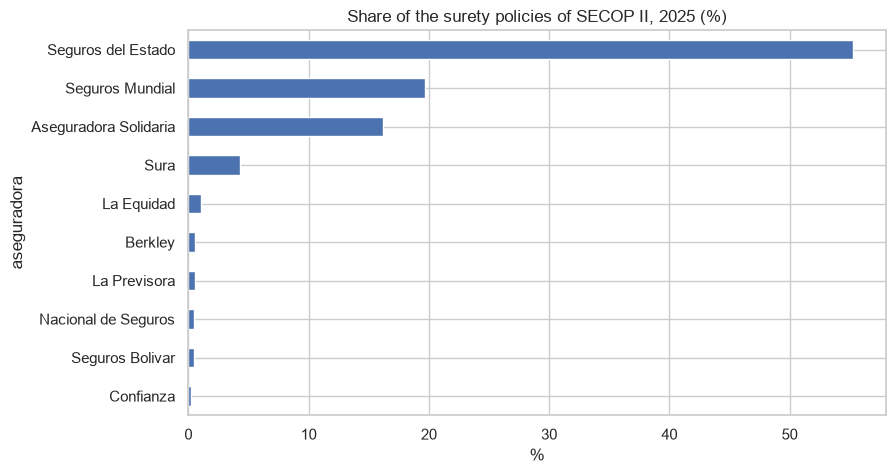

aseguradora
Seguros del Estado       55.2
Seguros Mundial          19.7
Aseguradora Solidaria    16.2
Sura                      4.3
La Equidad                1.1
Name: share, dtype: float64

In [5]:
cuota = ia[ia["year"] == 2025].set_index("aseguradora").sort_values("n", ascending=False)
plt.figure(figsize=(9, 5))
(cuota["share"].head(10) * 100).sort_values().plot.barh()
plt.title("Share of the surety policies of SECOP II, 2025 (%)")
plt.xlabel("%")
plt.savefig("figures/insurer_shares_2025.png", bbox_inches="tight")
plt.show()
(cuota["share"].head(5) * 100).round(1)

## Part 5. Clustering the insurers

For the insurers with at least 500 policies in 2025 we use: market share, growth 2023-2025, average insured value, % of rejected policies, % of policies above 1.000 million COP, and the solvency ratio of the Superintendencia (technical capital / required capital).

In [6]:
solv["valor"] = pd.to_numeric(solv["valor"])
solv["mes"] = solv["mes"].astype(int)
s = solv[(solv["mes"] == solv["mes"].max()) & solv["tipo_entidad"].astype(str).isin(["13", "15"])].copy()
s["aseguradora"] = s["nombre_entidad"].map(nombre)
pt = s[s["nombre_unidad_de_captura"].str.contains("PATRIMONIO TECNICO")].groupby("aseguradora")["valor"].sum()
pa = s[s["nombre_unidad_de_captura"].str.contains("PATRIMONIO ADECUADO")].groupby("aseguradora")["valor"].sum()

a = cuota[cuota["n"] >= 500][["n", "value", "share"]].copy()
a["growth_23_25"] = (a["n"] / ia[ia["year"] == 2023].set_index("aseguradora")["n"] - 1) * 100
a["avg_value_mill"] = a["value"] / a["n"] / 1e6
e = estado.groupby(["aseguradora", "estado"])["n"].sum().unstack().fillna(0)
a["rejected_%"] = (e.filter(regex="(?i)rechaz|devuel").sum(axis=1) / e.sum(axis=1) * 100).reindex(a.index).fillna(0)
a["large_%"] = (grandes.groupby("aseguradora")["n_large"].sum() / a["n"] * 100).reindex(a.index).fillna(0)
a["solvency"] = (pt / pa).reindex(a.index)
a = a.dropna(subset=["growth_23_25"])

x = a[["share", "growth_23_25", "avg_value_mill", "rejected_%", "large_%"]].copy()
x["share"], x["avg_value_mill"] = np.log(x["share"]), np.log(x["avg_value_mill"])
xs = StandardScaler().fit_transform(x)
for k in range(2, 7):
    print("k =", k, "| silhouette:", round(silhouette_score(xs, KMeans(k, n_init=50, random_state=0).fit_predict(xs)), 3))

k = 2 | silhouette: 0.32
k = 3 | silhouette: 0.3
k = 4 | silhouette: 0.313


k = 5 | silhouette: 0.317
k = 6 | silhouette: 0.326


In [7]:
km = KMeans(6, n_init=50, random_state=0).fit(xs)
a["cluster"] = km.labels_
for c in sorted(a["cluster"].unique()):
    print("Cluster", c, ":", ", ".join(a[a["cluster"] == c].index))
a[["share", "growth_23_25", "avg_value_mill", "rejected_%", "large_%", "solvency", "cluster"]].round(2).sort_values("cluster")

Cluster 0 : Berkley, Confianza, Zurich, AXA Colpatria, Mapfre
Cluster 1 : Seguros del Estado, Seguros Mundial, Aseguradora Solidaria, Sura
Cluster 2 : La Previsora, Seguros Bolivar, Segurexpo, JMalucelli Travelers, CESCE
Cluster 3 : La Equidad
Cluster 4 : Nacional de Seguros, HDI
Cluster 5 : Chubb, Liberty


,share,growth_23_25,avg_value_mill,rejected_%,large_%,solvency,cluster
aseguradora,,,,,,,
Berkley,0.01,56.56,2682.47,6.31,32.72,1.76,0
Confianza,0.00,-17.36,3258.33,6.21,11.43,3.63,0
Zurich,0.00,-25.19,5644.29,8.03,35.61,1.10,0
AXA Colpatria,0.00,-39.00,7723.80,4.64,45.49,1.86,0
Mapfre,0.00,18.20,4279.40,7.21,22.75,1.76,0
Seguros Mundial,0.20,33.00,482.30,5.39,4.28,1.36,1
Sura,0.04,-2.94,484.66,5.42,3.71,1.52,1
Seguros del Estado,0.55,15.31,332.96,5.91,2.97,1.64,1
Aseguradora Solidaria,0.16,3.11,364.23,4.75,1.62,4.45,1


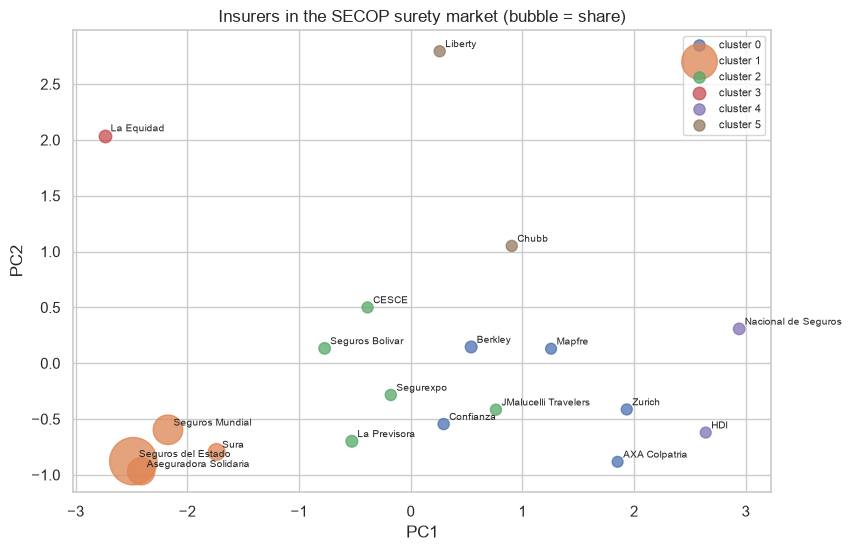

In [8]:
p = PCA(2).fit_transform(xs)
plt.figure(figsize=(9, 6))
for c in sorted(a["cluster"].unique()):
    mk = a["cluster"].values == c
    plt.scatter(p[mk, 0], p[mk, 1], s=60 + 2000 * a["share"].values[mk], alpha=0.75, label="cluster " + str(c))
for n_, (x1, y1) in zip(a.index, p):
    plt.annotate(n_, (x1, y1), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.title("Insurers in the SECOP surety market (bubble = share)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(fontsize=8)
plt.savefig("figures/insurer_clusters.png", bbox_inches="tight")
plt.show()

The silhouette is around 0.3 for every k, so the groups are not very separated. We take 6 because it is the highest, and the PCA shows the main idea: the 4 big mass-market insurers on one side, and on the other side the insurers specialised in big risks (very high average values and more rejections).

## Part 6. Segmenting the contractors (the clients of a broker)

For each contractor of 2025: number of policies, average insured value, number of different insurers, loyalty (share of the policies with its main insurer), if it is a consortium or "unión temporal", and if it is a company or a person.

In [9]:
c = contratistas.copy()
c["asegurado"] = c["asegurado"].fillna("").map(lambda s: re.sub(r"\s+", " ", sin_tildes(s)).strip().upper())
c = c.groupby(["asegurado", "aseguradora"], as_index=False)[["n", "value"]].sum()
g = c.groupby("asegurado")
cl = pd.DataFrame({"policies": g["n"].sum(), "value": g["value"].sum(), "insurers": g["aseguradora"].nunique(),
                   "loyalty": g["n"].max() / g["n"].sum()})
cl = cl[cl.index.str.len() > 2]
cl["avg_value"] = cl["value"] / cl["policies"]
cl["consortium"] = cl.index.str.contains(r"CONSORCIO|UNION TEMPORAL|\bUT\b", regex=True).astype(float)
cl["company"] = cl.index.str.contains(r"S\.?A\.?S|S\.?A\.?\b|LTDA|E\.?S\.?P|FUNDACI|CORPORACI|ASOCIACI|COOPERATIV|CONSORCIO|UNION TEMPORAL|GRUPO", regex=True).astype(float)
print("Contractors:", len(cl))

f = pd.DataFrame({"log_policies": np.log(cl["policies"]), "log_avg_value": np.log(cl["avg_value"]),
                  "log_insurers": np.log(cl["insurers"]), "loyalty": cl["loyalty"], "consortium": cl["consortium"], "company": cl["company"]})
fs = StandardScaler().fit_transform(f)
muestra = np.random.default_rng(0).choice(len(fs), 30000, replace=False)     # silhouette is slow, so we use a sample
for k in range(3, 8):
    print("k =", k, "| silhouette:", round(silhouette_score(fs[muestra], KMeans(k, n_init=10, random_state=0).fit_predict(fs[muestra])), 3))

Contractors: 276435


k = 3 | silhouette: 0.608


k = 4 | silhouette: 0.591


k = 5 | silhouette: 0.452


k = 6 | silhouette: 0.462


k = 7 | silhouette: 0.437


In [10]:
km = KMeans(3, n_init=20, random_state=0).fit(fs)
cl["segment"] = km.labels_
seg = cl.groupby("segment").agg(contractors=("policies", "size"), policies=("policies", "sum"), value=("value", "sum"),
                                median_policies=("policies", "median"), median_avg_value_mill=("avg_value", lambda v: v.median() / 1e6),
                                avg_insurers=("insurers", "mean"), loyalty=("loyalty", "mean"), consortium=("consortium", "mean"), company=("company", "mean"))
for col in ["contractors", "policies", "value"]:
    seg[col + "_%"] = seg[col] / seg[col].sum() * 100
seg = seg.drop(columns=["contractors", "policies", "value"])
seg.round(2).to_csv("data/contractor_segments_2025.csv")
seg.round(2)

,median_policies,median_avg_value_mill,avg_insurers,loyalty,consortium,company,contractors_%,policies_%,value_%
segment,,,,,,,,,
0,6.0,99.90,1.01,1.00,0.28,0.94,12.49,30.66,66.68
1,2.0,4.40,1.00,1.00,0.00,0.04,80.60,42.30,2.59
2,6.0,13.13,2.16,0.63,0.01,0.33,6.91,27.05,30.74


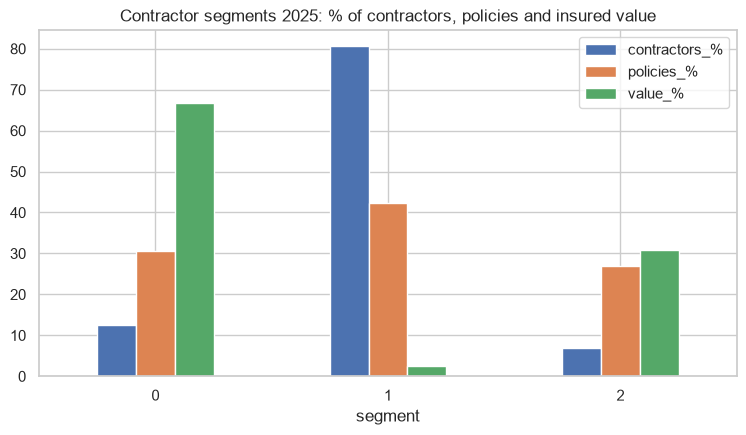

Contractors with more than 1 insurer: 7.0 %
Contractors with only 1 policy: 33.9 %


In [11]:
seg[["contractors_%", "policies_%", "value_%"]].plot.bar(figsize=(9, 4.5), rot=0)
plt.title("Contractor segments 2025: % of contractors, policies and insured value")
plt.savefig("figures/contractor_segments.png", bbox_inches="tight")
plt.show()
print("Contractors with more than 1 insurer:", round((cl["insurers"] > 1).mean() * 100, 1), "%")
print("Contractors with only 1 policy:", round((cl["policies"] == 1).mean() * 100, 1), "%")

## Conclusions

- The market is very concentrated: Seguros del Estado has more than half of the policies and the top 3 insurers have around 90%.
- The insurers form two big groups: the mass-market leaders (Estado, Mundial, Solidaria, Sura) with small average values, and the insurers specialised in big risks (Nacional de Seguros, HDI, Zurich, AXA Colpatria...) with average values of thousands of millions and more rejections.
- The contractors form 3 segments:
  - **Key accounts:** companies and consortia, few in number but with two thirds of the insured value, loyal to one insurer. For a broker they need account management.
  - **Multi-insurer contractors:** they already use 2 or more insurers, so they compare prices. They are the best target for a broker, because the value of a broker is to compare and place quickly.
  - **Individuals and micro contractors:** 80% of the contractors but only around 3% of the value. They need a simple, digital product, and a campaign before the January contracting peak.